# 06b. Modelo ResNet50 ajustada

Este cuaderno entrena una segunda version de ResNet50 con una receta de entrenamiento distinta a la
del procedimiento comun de las redes convolucionales. La ResNet50 del cuaderno 06 se conserva sin
cambios, porque sigue el mismo procedimiento que DenseNet121 y permite comparar arquitecturas. Esta
version responde a otra pregunta: cuanto mejora la misma arquitectura si se ajusta la receta.

La receta se eligio con experimentos sobre los tres primeros pliegues por campo del entrenamiento DR,
sin usar el conjunto de prueba. Las decisiones se tomaron en el pliegue 0 y se confirmaron en los
pliegues 1 y 2 con la politica fija, sin volver a elegir la epoca en cada pliegue.

## Entorno

In [1]:
import sys
from pathlib import Path


def raiz_proyecto():
    for candidato in [Path.cwd(), *Path.cwd().parents]:
        if (candidato / "src").is_dir():
            return candidato
    raise RuntimeError("No se encontro la raiz del proyecto")


RAIZ = raiz_proyecto()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

from matplotlib.ticker import MaxNLocator

from src.config import PALETA
from src.conjunto import cargar_conjunto
from src.evaluacion import cargar_resultados, metricas, tabla_predicciones
from src.graficos import aplicar_estilo, guardar_figura
from src.modelos_resnet import LADOS_AJUSTADA, PESOS_AJUSTADA, RECETA_AJUSTADA, dispositivo, ejecutar_resnet_ajustada

aplicar_estilo()
print(f"dispositivo: {dispositivo().type}, pesos: {PESOS_AJUSTADA.name}, lados evaluados: {LADOS_AJUSTADA}")
RECETA_AJUSTADA

dispositivo: cuda, pesos: IMAGENET1K_V2, lados evaluados: (224, 320)


{'tasa_aprendizaje': 0.001,
 'factor_base': 0.1,
 'descongelar': 'todo',
 'coseno': True,
 'epocas': 10,
 'tta': True}

## Receta

| Elemento | ResNet50 (cuaderno 06) | ResNet50 ajustada |
|:--|:--|:--|
| Pesos iniciales | `IMAGENET1K_V1` | `IMAGENET1K_V2` |
| Capas entrenadas | Cabeza o ultimo bloque | Toda la red |
| Tasa de aprendizaje | Una sola, `1e-4` o `3e-4` | `1e-3` en la salida y `1e-4` en el resto |
| Programa de la tasa | Constante | Coseno de 10 epocas |
| Seleccion de epoca | Parada temprana sobre validacion | Se conserva la ultima epoca |
| Tamano de entrada | 224 | 224 o 320, elegido en validacion |
| Prediccion | Imagen centrada | Promedio de la imagen y su reflejo horizontal |

Ajustar toda la red con una tasa menor en las capas preentrenadas permite adaptar los filtros
intermedios a las senales de sequia sin destruir lo aprendido en ImageNet. El programa coseno reduce
la tasa de forma gradual. Por eso las ultimas epocas cambian poco y no hace falta elegir una epoca
sobre un pliegue de validacion ruidoso. La entrada de 320 conserva mas detalle de fotografias que
miden 640 x 480. La perdida, el lote, la normalizacion y los aumentos son los del procedimiento comun.

## Ajuste y entrenamiento

In [2]:
conjunto = cargar_conjunto()
ruta = ejecutar_resnet_ajustada(conjunto)
resultados = cargar_resultados("resnet50_ajustada")
print(f"resultados guardados en: {ruta}")
print(f"tiempo de entrenamiento: {resultados.tiempo_entrenamiento_s / 60:.1f} min")
print(f"tiempo de inferencia: {resultados.tiempo_inferencia_ms:.2f} ms por imagen")
resultados.hiperparametros

Dispositivo: cuda. Ajuste: 2924, validacion: 731
Configuracion: lado=224


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /home/escu/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


  epoca 1: {'epoca': 1, 'perdida_entrenamiento': 0.047358428078376154, 'perdida_validacion': 0.03484727049735896, 'mae_validacion': 14.353355943912032} (43 s)


  epoca 2: {'epoca': 2, 'perdida_entrenamiento': 0.03211061344590298, 'perdida_validacion': 0.03504316867539397, 'mae_validacion': 14.334461300872093} (15 s)


  epoca 3: {'epoca': 3, 'perdida_entrenamiento': 0.02388556254709142, 'perdida_validacion': 0.03340272135279624, 'mae_validacion': 14.07164775884918} (16 s)


...

  epoca 8: {'epoca': 8, 'perdida_entrenamiento': 0.007901191450502576} (34 s)


  epoca 9: {'epoca': 9, 'perdida_entrenamiento': 0.006868180302360315} (35 s)


  epoca 10: {'epoca': 10, 'perdida_entrenamiento': 0.006432845589237239} (34 s)


resultados guardados en: /home/escu/Documentos/Universidad/Semestres/8voSemestre/DATA_SCIENCE/CC3084-Proyecto2/data/procesado/resultados/resnet50_ajustada.json
tiempo de entrenamiento: 17.0 min
tiempo de inferencia: 30.75 ms por imagen


{'tasa_aprendizaje': 0.001,
 'factor_base': 0.1,
 'descongelar': 'todo',
 'coseno': True,
 'epocas': 10,
 'tta': True,
 'lado': 320,
 'dispositivo': 'cuda',
 'pesos': 'IMAGENET1K_V2'}

## Historial del ajuste

Cada fila es la receta con un tamano de entrada, evaluada al final de las 10 epocas sobre el pliegue
de validacion.

In [3]:
historial = pd.DataFrame(
    [{"lado": paso.parametros["lado"], "rmse_validacion": paso.rmse_validacion, "mae_validacion": paso.mae_validacion, "elegido": paso.elegido}
     for paso in resultados.historial_ajuste]
)
historial.round(3)

,lado,rmse_validacion,mae_validacion,elegido
0,224,18.386,14.053,False
1,320,17.430,13.248,True


## Curva de entrenamiento de la configuracion elegida

,epoca,perdida_entrenamiento,perdida_validacion,mae_validacion
0,1,0.0446,0.0330,13.9102
1,2,0.0306,0.0315,13.5961
2,3,0.0228,0.0303,13.4919
3,4,0.0181,0.0342,14.1878
4,5,0.0149,0.0350,14.4263
5,6,0.0126,0.0314,13.4681
6,7,0.0101,0.0317,13.5817
7,8,0.0078,0.0294,12.9424
8,9,0.0076,0.0296,13.0908
9,10,0.0068,0.0304,13.2478


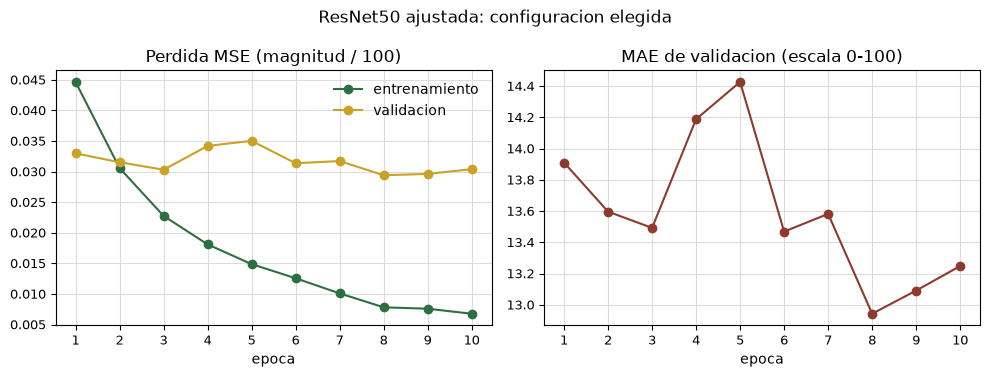

In [4]:
curva = pd.DataFrame([punto.model_dump() for punto in resultados.curva_entrenamiento])
fig, (ax_perdida, ax_mae) = plt.subplots(1, 2, figsize=(10, 3.8))
ax_perdida.plot(curva["epoca"], curva["perdida_entrenamiento"], marker="o", color=PALETA["principal"], label="entrenamiento")
ax_perdida.plot(curva["epoca"], curva["perdida_validacion"], marker="o", color=PALETA["secundario"], label="validacion")
ax_perdida.set_title("Perdida MSE (magnitud / 100)")
ax_perdida.set_xlabel("epoca")
ax_perdida.legend()
ax_mae.plot(curva["epoca"], curva["mae_validacion"], marker="o", color=PALETA["terciario"])
ax_mae.set_title("MAE de validacion (escala 0-100)")
ax_mae.set_xlabel("epoca")
for ax in (ax_perdida, ax_mae):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle("ResNet50 ajustada: configuracion elegida")
fig.tight_layout()
guardar_figura(fig, "06b_curva_resnet_ajustada")
curva.round(4)

## Resultados sobre la prueba frente a la ResNet50 del cuaderno 06

In [5]:
filas = {}
for modelo_id in ("resnet50", "resnet50_ajustada"):
    previos = cargar_resultados(modelo_id)
    if previos is None:
        continue
    tabla = tabla_predicciones(previos)
    sequia = tabla[tabla["dano"] == "DR"]
    filas[modelo_id] = {
        **{f"{k}_DR": v for k, v in metricas(sequia["real"], sequia["predicho"]).items() if k != "n"},
        "prediccion_media_real_10": sequia.loc[sequia["real"] == 10, "predicho"].mean(),
        "prediccion_media_real_90_100": sequia.loc[sequia["real"] >= 90, "predicho"].mean(),
        "entrenamiento_min": previos.tiempo_entrenamiento_s / 60,
        "inferencia_ms": previos.tiempo_inferencia_ms,
    }
pd.DataFrame(filas).T.round(3)

,mae_DR,rmse_DR,r2_DR,prediccion_media_real_10,prediccion_media_real_90_100,entrenamiento_min,inferencia_ms
resnet50,14.612,18.333,0.420,31.063,66.351,10.341,20.343
resnet50_ajustada,13.496,17.840,0.451,25.751,67.370,17.023,30.755
